# Systemy inspekcji wizualnej
## Laboratorium 2
Temat: Wczytywanie, wyświetlanie i zapisywanie obrazów oraz sekwencji obrazów w bibliotece OpenCV.

Instrukcję opracował: dr inż. Łukasz Jeleń

Wrocław 2026

---

Nazwisko i Imię:

Nr albumu:

Data wykonania ćwiczenia:

w celu zachowania przeniesienia do kolejnej linii należy się upewnić, że na końcu linii znajdują się 2 spacje

***

# 0. Zasady realizacji ćwiczenia

Notatnik składa się z dwóch części o odmiennym charakterze:

| Część | Charakter | Sposób realizacji | Punkty |
|---|---|---|---|
| **Sekcja 2 — Tutorial** | kod kompletny i uruchamialny, po każdym punkcie krótkie ćwiczenie kontrolne | komórki należy uruchamiać kolejno, zapoznając się z komentarzem, a następnie wykonać ćwiczenie **Do wykonania** | nd. |
| **Sekcja 3 — Zadania** | kod należy napisać samodzielnie | należy rozwiązać zadania i wypełnić komórki *Obserwacje i wnioski* | 30 |

Ćwiczenia kontrolne w sekcji 2 są krótkie — każde sprowadza się do modyfikacji kodu przedstawionego bezpośrednio nad nim — lecz ich wykonanie jest warunkiem zaliczenia ćwiczenia.

**Zakres pracy.** Należy przesłać niniejszy notatnik z uzupełnioną **sekcją 2 i sekcją 3**, **wykonanymi komórkami** (widoczne wyniki) oraz wypełnionymi komórkami *Obserwacje i wnioski*. Notatnik bez wypełnionych obserwacji nie podlega ocenie.

**Nazwa pliku:** `Lab2_Nazwisko_NrAlbumu.ipynb`. Notatnik należy przesłać przez e-portal.

***

# 1. Narzędzia

Na zajęciach będziemy korzystali z Pythona, który jest stosunkowo prostym językiem programowania. Mają Państwo do wyboru korzystanie z Google Colab (https://colab.research.google.com) - wersja online, lub Anaconda Navigator (https://www.anaconda.com/), ale ta  wymaga instalacji na własnym komputerze. Są to oczywiście tylko propozycje.

**Trzy uwagi pozwalające uniknąć najczęstszych błędów:**

1. `cv2.imshow()` **nie działa** ani w Jupyterze, ani w Colabie - zawiesza jądro. Wyświetlamy przez `matplotlib`.
2. `cv2.imread()` przy błędnej ścieżce **nie zgłasza błędu** - po cichu zwraca `None`, a program wywala się dopiero kilka linii dalej, w zupełnie innym miejscu. Dlatego poniżej jest funkcja `wczytaj()`, która to sprawdza.
3. OpenCV trzyma kanały w kolejności **BGR**, a `matplotlib` oczekuje **RGB**. Zagadnienie to omówiono w punkcie 2.1.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("OpenCV:", cv2.__version__)

DANE = Path(".")          # katalog z obrazami - dostosuj do siebie
WYNIKI = Path("wyniki")   # katalog na pliki zapisywane przez notatnik
WYNIKI.mkdir(exist_ok=True)


def wczytaj(nazwa, flaga=cv2.IMREAD_COLOR):
    """Wczytuje obraz i zglasza czytelny blad, gdy pliku nie ma."""
    sciezka = DANE / nazwa
    obraz = cv2.imread(str(sciezka), flaga)
    if obraz is None:
        raise FileNotFoundError(f"Nie udalo sie wczytac: {sciezka.resolve()}")
    return obraz


def pokaz(*obrazy, tytuly=None, cmap="gray", rozmiar=4):
    """Wyswietla jeden lub wiele obrazow obok siebie.

    Dla obrazow 1-kanalowych uzywa cmap i stalego zakresu 0-255,
    dla 3-kanalowych zaklada, ze podano je juz w RGB.
    """
    n = len(obrazy)
    fig, osie = plt.subplots(1, n, figsize=(rozmiar * n, rozmiar))
    if n == 1:
        osie = [osie]
    for i, (ax, img) in enumerate(zip(osie, obrazy)):
        if img.ndim == 2:
            ax.imshow(img, cmap=cmap, vmin=0, vmax=255)
        else:
            ax.imshow(img)
        ax.set_title(tytuly[i] if tytuly else "")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

W Google Colab pliki wgrywamy przez panel po lewej stronie albo poleceniem:

```python
from google.colab import files
files.upload()
```

## 1.1 Dane do ćwiczenia

W komórce poniżej **generowany jest komplet obrazów testowych**, dzięki czemu notatnik działa bez konieczności pobierania dodatkowych plików. Komórkę należy uruchomić tylko raz.

W przypadku korzystania z obrazów udostępnionych na e-portalu należy podmienić nazwy plików w dalszych komórkach; logika pozostaje bez zmian.

In [ ]:
def wzorzec_paskowy(h=238, w=225, tlo=10, pasek=190):
    """Pionowy wzorzec paskowy (bar target) o rosnacej szerokosci paskow."""
    img = np.full((h, w), tlo, np.uint8)
    x, szer = 0, 1
    while x < w:
        img[:, x:min(x + szer, w)] = pasek
        x += 2 * szer
        szer += 1
    return img


def scena_kolorowa(h=240, w=320):
    """Prosta scena z obiektami o czystych barwach - do cwiczen z kanalami."""
    img = np.full((h, w, 3), 230, np.uint8)          # jasne tlo (BGR)
    cv2.rectangle(img, (20, 40), (110, 150), (40, 40, 220), -1)    # czerwony
    cv2.circle(img, (175, 95), 55, (60, 180, 60), -1)              # zielony
    cv2.rectangle(img, (235, 40), (305, 150), (210, 90, 40), -1)   # niebieski
    cv2.putText(img, "SIW", (30, 215), cv2.FONT_HERSHEY_SIMPLEX, 2.0, (30, 30, 30), 4)
    return img


def tarcza_tnaca(h=240, w=240, uszkodzona=False, ziarno=0):
    """Tarcza tnaca do szlifierki katowej - egzemplarz wzorcowy i z wadami.

    """
    rng = np.random.default_rng(ziarno)
    srodek = (w // 2, h // 2)
    R, r_otw = 105, 24

    y, x = np.indices((h, w))
    faktura = (62.0
               + rng.normal(0, 6.0, (h, w))                     # ziarno sciernicy
               + 7.0 * ((x + y) % 7 < 2)                        # zbrojenie, splot 1
               + 7.0 * ((x - y) % 7 < 2))                       # zbrojenie, splot 2
    faktura = np.clip(faktura, 0, 255).astype(np.uint8)

    maska = np.zeros((h, w), np.uint8)
    cv2.circle(maska, srodek, R, 255, -1)            # korpus tarczy
    cv2.circle(maska, srodek, r_otw, 0, -1)          # otwor montazowy

    if uszkodzona:
        # wyszczerbienie krawedzi tnacej
        cv2.circle(maska, (srodek[0] + 93, srodek[1] - 46), 17, 0, -1)
        # peknięcie promieniowe od otworu
        cv2.line(maska, (srodek[0] - 30, srodek[1] + 26),
                        (srodek[0] - 72, srodek[1] + 64), 0, 3)

    img = np.full((h, w), 228, np.uint8)             # tlo stanowiska
    img[maska > 0] = faktura[maska > 0]
    return img


def nierowne_oswietlenie(h=240, w=320):
    """Jasny obiekt na tle z silnym gradientem oswietlenia."""
    gradient = np.tile(np.linspace(40, 215, w, dtype=np.float32), (h, 1))
    img = gradient.copy()
    cv2.putText(img, "INSPEKCJA", (15, 140), cv2.FONT_HERSHEY_SIMPLEX, 1.1, 20, 3)
    cv2.rectangle(img, (30, 170), (290, 200), 25, -1)
    return np.clip(img, 0, 255).astype(np.uint8)


def sekwencja_testowa(plik, n=120, h=240, w=320, fps=25):
    """Krotka sekwencja: jasny kwadrat przesuwajacy sie w poziomie."""
    zapis = cv2.VideoWriter(str(plik), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
    for k in range(n):
        klatka = np.full((h, w, 3), 35, np.uint8)
        x = int(20 + (w - 80) * k / n)
        cv2.rectangle(klatka, (x, 90), (x + 50, 140), (80, 200, 230), -1)
        cv2.putText(klatka, f"{k:03d}", (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1)
        zapis.write(klatka)
    zapis.release()


cv2.imwrite(str(DANE / "wzorzec_paskowy.png"), wzorzec_paskowy())
cv2.imwrite(str(DANE / "scena.png"), scena_kolorowa())
cv2.imwrite(str(DANE / "tarcza_wzorzec.png"), tarcza_tnaca(uszkodzona=False))
cv2.imwrite(str(DANE / "tarcza_badana.png"), tarcza_tnaca(uszkodzona=True))
cv2.imwrite(str(DANE / "nierowne.png"), nierowne_oswietlenie())
sekwencja_testowa(DANE / "sekwencja.mp4")

print("Wygenerowano pliki:")
for p in sorted(DANE.glob("*")):
    if p.suffix in {".png", ".mp4"}:
        print(" ", p.name, p.stat().st_size, "B")

***

# 2. Tutorial

Komórki należy uruchamiać kolejno, zapoznając się z komentarzem. Z przedstawionych tu rozwiązań należy korzystać przy realizacji zadań z sekcji 3.

Każdy punkt zakończony jest krótkim ćwiczeniem **Do wykonania**, stanowiącym modyfikację kodu przedstawionego wcześniej.

## 2.1 Wczytanie obrazu i pułapka BGR

`cv2.imread()` zwraca tablicę NumPy z kanałami w kolejności **B, G, R**. `plt.imshow()` interpretuje trzeci wymiar jako **R, G, B**. Jeżeli nie wykonamy konwersji, czerwony i niebieski zamienią się miejscami.

In [ ]:
bgr = wczytaj("scena.png")
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

pokaz(bgr, rgb, tytuly=["bez konwersji (zle)", "po COLOR_BGR2RGB (dobrze)"])

print("Piksel (95, 60) jako BGR:", bgr[95, 60])
print("Piksel (95, 60) jako RGB:", rgb[95, 60])

Należy zwrócić uwagę, że **indeks ma postać `[wiersz, kolumna]`, czyli `[y, x]`**, czyli odwrotnie niż w zapisie współrzędnych punktu. Jest to źródło znacznej części pomyłek na początkowym etapie pracy.

Błąd BGR/RGB nie ujawni się na obrazie w odcieniach szarości ani na zdjęciu o stonowanych barwach. Z tego powodu bywa wykrywany dopiero na końcowym etapie pracy.

### Do wykonania 2.1

Konwersję BGR -> RGB można wykonać również zwykłym odwróceniem kolejności kanałów: `obraz[:, :, ::-1]`.

Należy wyznaczyć oba warianty i sprawdzić funkcją `np.array_equal`, czy dają taki sam wynik. Dodatkowo należy podać wartość piksela o współrzędnych `y = 95`, `x = 265` w obu zapisach i wskazać, który obiekt sceny się w nim znajduje.

In [ ]:
# TODO

## 2.2 Anatomia obrazu

Obraz jest zwykłą tablicą NumPy. Typ danych i zakres wartości należy ustalić na samym początku, ponieważ arytmetyka na typie `uint8` zachowuje się inaczej, niż wynikałoby to z intuicji.

In [ ]:
szary = wczytaj("wzorzec_paskowy.png", cv2.IMREAD_GRAYSCALE)

print("ksztalt (h, w)      :", szary.shape)
print("typ danych          :", szary.dtype)
print("min / max           :", szary.min(), "/", szary.max())
print("liczba pikseli      :", szary.size)
print("unikalne poziomy    :", np.unique(szary))

# UWAGA: arytmetyka na uint8 ZAWIJA SIE, funkcje OpenCV NASYCAJA
a = np.array([[250]], np.uint8)
b = np.array([[ 10]], np.uint8)
c = np.array([[  5]], np.uint8)
d = np.array([[ 20]], np.uint8)

print("\n  250 + 10  operatorem '+' :", (a + b).ravel()[0], "  <- przepelnienie, zawinelo sie")
print("  250 + 10  cv2.add        :", cv2.add(a, b).ravel()[0], "  <- nasycenie do 255")
print("    5 - 20  operatorem '-' :", (c - d).ravel()[0], "  <- wartosc ujemna zawinela sie w gore")
print("    5 - 20  cv2.subtract   :", cv2.subtract(c, d).ravel()[0], "  <- obciecie do 0")
print("    5 - 20  cv2.absdiff    :", cv2.absdiff(c, d).ravel()[0], "  <- modul roznicy")

W inspekcji wizualnej, ta rónica zamienia defekt w szum: przy odejmowaniu obrazów operator `-` na `uint8` zawija wartości ujemne do okolic 255, czyli **tworzy fałszywe jasne obszary tam, gdzie obraz badany jest ciemniejszy od wzorca**. Z tego powodu stosuje się `cv2.absdiff()` albo `cv2.subtract()`.

In [ ]:
# ROI to WIDOK na oryginalna tablice, nie kopia
obraz = wczytaj("scena.png")
roi = obraz[40:150, 20:110]          # [y1:y2, x1:x2]
roi[:] = 0                            # modyfikujemy ROI...
pokaz(cv2.cvtColor(obraz, cv2.COLOR_BGR2RGB), tytuly=["...a zmienil sie oryginal"])

# zeby tego uniknac:
obraz = wczytaj("scena.png")
roi_kopia = obraz[40:150, 20:110].copy()
roi_kopia[:] = 0
pokaz(cv2.cvtColor(obraz, cv2.COLOR_BGR2RGB), tytuly=["po .copy() oryginal nietkniety"])

### Do wykonania 2.2

Należy rozjaśnić obraz `scena.png` o 40 poziomów dwoma sposobami: operatorem `+` na tablicy `uint8` oraz funkcją `cv2.add`.

Należy wyświetlić oba wyniki, wyznaczyć "mapę różnicy" między tymi obrazami (obraz powstały jako ich róźnica) i wskazać, w których obszarach obrazu wyniki się różnią oraz z czego to wynika.

In [ ]:
# TODO

## 2.3 Kanały barwne

`cv2.split()` rozdziela obraz na kanały, `cv2.merge()` składa je z powrotem. Pojedynczy kanał jest obrazem jednokanałowym, który wyświetlamy w odcieniach szarości.

In [ ]:
bgr = wczytaj("scena.png")
B, G, R = cv2.split(bgr)

pokaz(R, G, B, tytuly=["kanal R", "kanal G", "kanal B"])

# ten sam kanal wyswietlony bez cmap='gray' - matplotlib dokleja wlasna mape kolorow
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(R, cmap="gray", vmin=0, vmax=255); ax[0].set_title("cmap='gray'"); ax[0].axis("off")
ax[1].imshow(R);                                 ax[1].set_title("domyslna mapa (mylace)"); ax[1].axis("off")
plt.tight_layout(); plt.show()

print("Sredni poziom w obszarze czerwonego prostokata:")
for nazwa, kanal in zip("BGR", (B, G, R)):
    print(f"  kanal {nazwa}: {kanal[40:150, 20:110].mean():6.1f}")

Czerwony obiekt jest **najjaśniejszy w kanale R i najciemniejszy w B**. Jest to podstawa najtańszej selekcji barwnej w inspekcji, tzn. zamiast analizować kolor, dobiera się oświetlenie i kanał tak, żeby interesujący nas obiekt miał maksymalny kontrast.

### Do wykonania 2.3

Przy pomocy `cv2.split` i `cv2.merge` należy złożyć obraz z zamienionymi kanałami R i B, a następnie poprawnie go wyświetlić.

Należy takze podać, na którym z kanałów napis „SIW" ma **najmniejszy** kontrast względem tła. Wartość należy uzasadnić liczbowo, a nie "na oko".

In [ ]:
# TODO

## 2.4 Konwersja do odcieni szarości

`cv2.cvtColor` nie liczy zwykłej średniej kanałów, tylko stosuje wagi luminancji (0,299 R + 0,587 G + 0,114 B), odpowiadające czułości oka człowieka.

In [ ]:
bgr = wczytaj("scena.png")
szary_cv = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
szary_sr = bgr.mean(axis=2).astype(np.uint8)

roznica = cv2.absdiff(szary_cv, szary_sr)
pokaz(szary_cv, szary_sr, roznica,
      tytuly=["cvtColor (wagi luminancji)", "zwykla srednia", "roznica bezwzgledna"])
print("roznica: max =", roznica.max(), " srednia =", round(float(roznica.mean()), 2))

### Do wykonania 2.4

Należy obliczyć obraz w odcieniach szarości ręcznie, według wzoru `0.299·R + 0.587·G + 0.114·B`, wykonując obliczenia na typie `float32`, a następnie zaokrąglić wynik do `uint8`.

Należy sprawdzić, czy wynik jest identyczny z wynikiem `cv2.cvtColor`. Jeżeli nie, to proszę podać maksymalną różnicę i wyjaśnić jej przyczynę.

In [ ]:
# TODO

## 2.5 Przekształcenia geometryczne

**Skalowanie.** Metoda interpolacji ma znaczenie i jest inna przy pomniejszaniu niż przy powiększaniu. `INTER_AREA` uśrednia piksel po pikselu i jest właściwa do pomniejszania; `INTER_NEAREST` usuwa co drugi wiersz i kolumnę, co na wzorcu paskowym prowadzi do **aliasingu**.

In [ ]:
wzorzec = wczytaj("wzorzec_paskowy.png", cv2.IMREAD_GRAYSCALE)
metody = [("INTER_NEAREST", cv2.INTER_NEAREST),
          ("INTER_LINEAR",  cv2.INTER_LINEAR),
          ("INTER_AREA",    cv2.INTER_AREA)]

male = [cv2.resize(wzorzec, None, fx=0.25, fy=0.25, interpolation=m) for _, m in metody]
lupa = [cv2.resize(m[20:60, 0:40], None, fx=6, fy=6, interpolation=cv2.INTER_NEAREST) for m in male]
pokaz(*lupa, tytuly=[n for n, _ in metody])

**Obrót bez obcięcia narożników.** `getRotationMatrix2D` obraca względem zadanego punktu, ale `warpAffine` rysuje wynik na scenie (canvas) o rozmiarze, który sami podamy. Jeżeli podamy rozmiar oryginału, narożniki wyjdą poza kadr. Trzeba przeliczyć nowy rozmiar i dołożyć przesunięcie do macierzy.

In [ ]:
def obroc(obraz, kat):
    h, w = obraz.shape[:2]
    srodek = (w / 2.0, h / 2.0)
    M = cv2.getRotationMatrix2D(srodek, kat, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    nW = int(h * sin + w * cos)
    nH = int(h * cos + w * sin)
    M[0, 2] += nW / 2.0 - srodek[0]      # dosuniecie do nowego plotna
    M[1, 2] += nH / 2.0 - srodek[1]
    return cv2.warpAffine(obraz, M, (nW, nH))


scena = cv2.cvtColor(wczytaj("scena.png"), cv2.COLOR_BGR2RGB)
h, w = scena.shape[:2]
M_zle = cv2.getRotationMatrix2D((w / 2.0, h / 2.0), 30, 1.0)
zle = cv2.warpAffine(scena, M_zle, (w, h))

pokaz(zle, obroc(scena, 30), tytuly=["rozmiar oryginalu - narozniki obciete", "rozmiar przeliczony"])

**Przycięcie (ROI).** Zwykłe indeksowanie NumPy, kolejność `[y1:y2, x1:x2]`.

In [ ]:
scena = cv2.cvtColor(wczytaj("scena.png"), cv2.COLOR_BGR2RGB)
x, y, szer, wys = 120, 40, 110, 110
roi = scena[y:y + wys, x:x + szer].copy()
print("ROI ma ksztalt:", roi.shape)
pokaz(scena, roi, tytuly=["oryginal", f"ROI {szer}x{wys} od ({x},{y})"])

### Do wykonania 2.5

Wzorzec paskowy należy przeskalować do 40 % rozmiaru metodami `INTER_NEAREST` oraz `INTER_AREA` i dla każdego wyniku podać **liczbę unikalnych poziomów jasności** (`np.unique`).

Należy wyjaśnić, dlaczego liczby te się różnią, mimo że obraz wejściowy zawiera tylko dwa poziomy.

In [ ]:
# TODO

## 2.6 Progowanie i histogram

Trzy warianty, które trzeba znać:

- **próg stały** - jedna liczba dla całego obrazu, podana ręcznie;
- **Otsu** - próg globalny, ale wyznaczony automatycznie z histogramu (maksymalizuje rozdzielenie dwóch klas);
- **progowanie adaptacyjne** - próg liczony lokalnie, w otoczeniu każdego piksela.

In [ ]:
szary = wczytaj("nierowne.png", cv2.IMREAD_GRAYSCALE)

_, b_staly = cv2.threshold(szary, 127, 255, cv2.THRESH_BINARY)
prog_otsu, b_otsu = cv2.threshold(szary, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
b_adapt = cv2.adaptiveThreshold(szary, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                cv2.THRESH_BINARY, blockSize=35, C=7)

print("prog wyznaczony przez Otsu:", prog_otsu)
pokaz(szary, b_staly, b_otsu, b_adapt,
      tytuly=["oryginal (gradient!)", "prog staly 127", f"Otsu ({prog_otsu:.0f})", "adaptacyjny"],
      rozmiar=3.2)

Na obrazie z gradientem oświetlenia **żaden próg globalny nie zadziała**, poniwaz ta sama wartość jest tłem po lewej stronie i obiektem po prawej. To nie jest problem algorytmu, tylko problem oświetlenia stanowiska: w prawdziwym systemie inspekcyjnym naprawia się to doświetleniem, a nie progowaniem adaptacyjnym.

**Histogram** pokazuje, dlaczego tak jest.

In [ ]:
szary = wczytaj("wzorzec_paskowy.png", cv2.IMREAD_GRAYSCALE)
prog_otsu, _ = cv2.threshold(szary, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
hist = cv2.calcHist([szary], [0], None, [256], [0, 256]).ravel()

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].imshow(szary, cmap="gray", vmin=0, vmax=255); ax[0].set_title("obraz"); ax[0].axis("off")
ax[1].plot(hist); ax[1].axvline(prog_otsu, color="r", ls="--", label=f"Otsu = {prog_otsu:.0f}")
ax[1].set_title("histogram"); ax[1].set_xlabel("poziom jasnosci"); ax[1].legend()
ax[2].plot(np.cumsum(hist) / hist.sum()); ax[2].set_title("histogram skumulowany")
ax[2].set_xlabel("poziom jasnosci"); ax[2].set_ylim(0, 1)
plt.tight_layout(); plt.show()

### Do wykonania 2.6

Dla obrazu `nierowne.png` należy wyznaczyć próg metodą Otsu **trzykrotnie**: dla całego obrazu, dla jego lewej połowy oraz dla prawej połowy.

Należy zestawić trzy otrzymane wartości i na tej podstawie wyjaśnić, dlaczego pojedynczy próg globalny nie jest w stanie poprawnie zbinaryzować całego obrazu.

In [ ]:
# TODO

## 2.7 Zapis obrazu i formaty

`cv2.imwrite()` wybiera format po rozszerzeniu pliku. Trzeci argument to lista parametrów: 

dla JPEG jakość 0–100, 

dla PNG stopień kompresji 0–9 (bezstratny niezależnie od wartości).

In [ ]:
wzorzec = wczytaj("wzorzec_paskowy.png", cv2.IMREAD_GRAYSCALE)

warianty = [("wzorzec.png",     [cv2.IMWRITE_PNG_COMPRESSION, 9]),
            ("wzorzec_q90.jpg", [cv2.IMWRITE_JPEG_QUALITY, 90]),
            ("wzorzec_q30.jpg", [cv2.IMWRITE_JPEG_QUALITY, 30])]

odczytane, podpisy = [], []
for nazwa, parametry in warianty:
    sciezka = WYNIKI / nazwa
    cv2.imwrite(str(sciezka), wzorzec, parametry)
    wrocil = cv2.imread(str(sciezka), cv2.IMREAD_GRAYSCALE)
    roznica = cv2.absdiff(wzorzec, wrocil)
    print(f"{nazwa:16s} {sciezka.stat().st_size:7d} B   "
          f"roznica max={roznica.max():3d}  srednia={roznica.mean():5.2f}")
    odczytane.append(roznica)
    podpisy.append(nazwa)

pokaz(*odczytane, tytuly=podpisy)

Dla PNG różnica jest dokładnie zerowa, a zapis jest bezstratny. Dla JPEG wokół krawędzi pasków pojawiają się **artefakty blokowe i efekt dzwonienia** (*ringing*), tym silniejsze, im niższa jakość.

Należy zwrócić uwagę na rozmiary plików: dla tego obrazu **PNG jest wielokrotnie mniejszy od JPEG**, mimo że jest bezstratny. JPEG został zaprojektowany pod zdjęcia o łagodnych przejściach tonalnych i radzi sobie fatalnie z grafiką o ostrych krawędziach i małej liczbie poziomów. Odwrotna sytuacja wystąpi dla zdjęcia twarzy.

Konsekwencja dla inspekcji wizualnej: artefakt kompresji wygląda w algorytmie dokładnie tak samo jak drobna wada powierzchni. Dlatego obrazy na potrzeby inspekcji archiwizuje się bezstratnie.

### Do wykonania 2.7

Należy powtórzyć porównanie formatów z powyższej komórki dla obrazu `scena.png` (jakość JPEG 90 i 30) i zestawić wyniki z wynikami uzyskanymi dla wzorca paskowego.

Należy wskazać, dla którego z dwóch obrazów format JPEG wypada korzystniej zarówno pod względem rozmiaru pliku, jak i wielkości błędu  oraz wyjaśnić, jaka cecha zawartości obrazu o tym decyduje.

In [ ]:
# TODO

## 2.8 Sekwencje obrazów

`cv2.VideoCapture` otwiera plik wideo albo kamerę, `cv2.VideoWriter` zapisuje. Obiekty trzeba zwolnić metodą `.release()`.

In [ ]:
wej = cv2.VideoCapture(str(DANE / "sekwencja.mp4"))

n_klatek = int(wej.get(cv2.CAP_PROP_FRAME_COUNT))
fps      = wej.get(cv2.CAP_PROP_FPS)
szer     = int(wej.get(cv2.CAP_PROP_FRAME_WIDTH))
wys      = int(wej.get(cv2.CAP_PROP_FRAME_HEIGHT))
print(f"klatek: {n_klatek}, fps: {fps:.1f}, rozdzielczosc: {szer}x{wys}, "
      f"czas: {n_klatek / fps:.1f} s")

wybrane, podpisy = [], []
i = 0
while True:
    ok, klatka = wej.read()
    if not ok:
        break
    if i % 30 == 0:
        wybrane.append(cv2.cvtColor(klatka, cv2.COLOR_BGR2RGB))
        podpisy.append(f"klatka {i}")
    i += 1
wej.release()
print("faktycznie odczytano klatek:", i)

pokaz(*wybrane, tytuly=podpisy, rozmiar=3)

Należy porównać wartość `CAP_PROP_FRAME_COUNT` z liczbą faktycznie odczytanych klatek. Dla wielu kontenerów ta pierwsza wartość jest jedynie szacunkiem z nagłówka pliku i potrafi się nie zgadzać.

Zapis przetworzonej sekwencji: `fourcc` to czteroznakowy kod kodeka, a **rozmiar podany w konstruktorze musi dokładnie odpowiadać rozmiarowi zapisywanych klatek** inaczej powstanie pusty plik, bez żadnego komunikatu o błędzie.

In [ ]:
wej = cv2.VideoCapture(str(DANE / "sekwencja.mp4"))
fps  = wej.get(cv2.CAP_PROP_FPS)
szer = int(wej.get(cv2.CAP_PROP_FRAME_WIDTH))
wys  = int(wej.get(cv2.CAP_PROP_FRAME_HEIGHT))

wyj = cv2.VideoWriter(str(WYNIKI / "sekwencja_szara.mp4"),
                      cv2.VideoWriter_fourcc(*"mp4v"), fps, (szer, wys))

zapisane = 0
while True:
    ok, klatka = wej.read()
    if not ok:
        break
    szara = cv2.cvtColor(klatka, cv2.COLOR_BGR2GRAY)
    wyj.write(cv2.cvtColor(szara, cv2.COLOR_GRAY2BGR))   # VideoWriter oczekuje 3 kanalow
    zapisane += 1

wej.release()
wyj.release()

kontrola = cv2.VideoCapture(str(WYNIKI / "sekwencja_szara.mp4"))
print("zapisano klatek :", zapisane)
print("plik ma rozmiar :", (WYNIKI / "sekwencja_szara.mp4").stat().st_size, "B")
print("odczyt zwrotny  :", int(kontrola.get(cv2.CAP_PROP_FRAME_COUNT)), "klatek")
kontrola.release()

### Do wykonania 2.8

Dla sekwencji `sekwencja.mp4` należy wyznaczyć **średnią jasność każdej klatki** i wykreślić ją w funkcji numeru klatki.

Należy podać numer klatki o największej średniej jasności oraz wyjaśnić przebieg otrzymanej krzywej w odniesieniu do zawartości sekwencji.

In [ ]:
# TODO

## 2.9 Inspekcja przez porównanie ze wzorcem

Przedmiotem inspekcji jest **tarcza tnąca do szlifierki kątowej**: należy stwierdzić, czy badany egzemplarz nosi ślady wyszczerbienia krawędzi tnącej lub pęknięcia korpusu. Zastosowana zostanie najprostsza znana metoda inspekcji, stanowiąca wciąż podstawę przemysłowych SIW: obraz badany odejmuje się od wzorcowego, a to, co zostaje, uznaje się za wadę.

In [ ]:
wzorzec = wczytaj("tarcza_wzorzec.png", cv2.IMREAD_GRAYSCALE)
badana  = wczytaj("tarcza_badana.png",  cv2.IMREAD_GRAYSCALE)

zle   = badana - wzorzec                  # uint8: wartosci ujemne zawijaja sie!
dobrze = cv2.absdiff(badana, wzorzec)

pokaz(wzorzec, badana, zle, dobrze,
      tytuly=["tarcza wzorcowa", "tarcza badana", "operator '-' (zle)", "cv2.absdiff (dobrze)"], rozmiar=3.2)

In [ ]:
_, maska = cv2.threshold(dobrze, 40, 255, cv2.THRESH_BINARY)
n, etykiety, staty, srodki = cv2.connectedComponentsWithStats(maska, connectivity=8)

wynik = cv2.cvtColor(badana, cv2.COLOR_GRAY2BGR)
znalezione = 0
for i in range(1, n):                       # etykieta 0 to tlo
    x, y, w_, h_, pole = staty[i]
    if pole < 20:                           # odrzucamy drobiazgi
        continue
    znalezione += 1
    cv2.rectangle(wynik, (x, y), (x + w_, y + h_), (0, 0, 255), 2)
    print(f"defekt {znalezione}: pole={pole:4d} px, bbox=({x},{y},{w_},{h_})")

print("\nlacznie defektow:", znalezione)
pokaz(maska, cv2.cvtColor(wynik, cv2.COLOR_BGR2RGB), tytuly=["maska wady", "wynik inspekcji"])

Metoda działa przy dwóch założeniach: 

obraz badany jest **dokładnie spasowany** ze wzorcem (brak przesunięcia, obrotu, zmiany skali) 

oraz ma **tę samą jasność**. Oba założenia łatwo naruszyć, czego dotyczą zadania 5 i 6.

### Do wykonania 2.9

Należy powtórzyć detekcję wad z powyższej komórki dla progu binaryzacji równego 15, 40 oraz 90, pozostawiając `min_pole = 20`.

Dla każdej wartości progu należy podać liczbę wykrytych obszarów oraz ich łączne pole, a wyniki zestawić w tabeli. Należy wskazać, przy którym progu pojawiają się fałszywe alarmy, a przy którym wada zostaje przeoczona.

In [ ]:
# TODO

***

# 3. Zadania na ocenę

Zadania 1–5 są obowiązkowe, zadania 6–7 dodatkowe. Przy każdym zadaniu należy wypełnić komórkę *Obserwacje i wnioski*; sam kod bez wniosków nie wystarcza do zaliczenia.

| Zadanie | Temat | Punkty |
|---|---|---|
| 1 | Obraz syntetyczny — wzorzec paskowy | 5 |
| 2 | Zapis i formaty — wpływ kompresji | 5 |
| 3 | Szum impulsowy jako funkcja z parametrem | 5 |
| 4 | Progowanie przy nierównomiernym oświetleniu | 5 |
| 5 | Inspekcja przez porównanie z wzorcem | 10 |
| 6 | (dodatkowe) Odporność na przesunięcie i jasność | 5 |
| 7 | (dodatkowe) Detekcja defektu w sekwencji | 5 |

**Razem: sekcja 2 — 10 pkt, sekcja 3 (zadania obowiązkowe) — 30 pkt. Próg zaliczenia ćwiczenia: 20 pkt.**

Funkcje należy implementować **dokładnie z podanymi sygnaturami**, co usprawnia sprawdzanie prac.

## Zadanie 1 (5 pkt)

Należy napisać funkcję `moj_wzorzec(h, w, tlo, pasek)` tworzącą obraz przedstawiony na poniższym przykładzie, a wynik zapisać na dysku pod nazwą `zad1_wzorzec.png`.

**Specyfikacja:** obraz 8-bitowy, jednokanałowy, o rozmiarze 238×225 px (wys.×szer.). Tło o poziomie jasności 10. Na tle pionowe, jasne paski o poziomie 190, rozciągające się na całą wysokość obrazu. Szerokość pasków rośnie od lewej do prawej, zaczynając od 1 px; odstęp między sąsiednimi paskami jest równy szerokości paska po jego lewej stronie. Jest to **wzorzec paskowy** (*bar target*), używany do oceny rozdzielczości układu obrazowania.

Nie należy kopiować funkcji z sekcji 1.1. Po utworzeniu obrazu należy **zweryfikować wynik**: wypisać kształt, typ danych, zbiór występujących poziomów jasności oraz liczbę pasków.

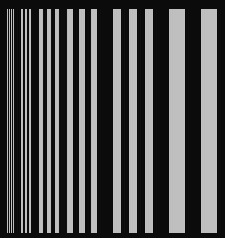

In [ ]:
def moj_wzorzec(h=238, w=225, tlo=10, pasek=190):
    # TODO
    pass


# TODO: utworz, sprawdz wlasciwosci, wyswietl i zapisz jako zad1_wzorzec.png

**Obserwacje i wnioski**

*Ile pasków zmieściło się w obrazie i z czego wynika ta liczba? Przy rejestracji wzorca układem o zbyt małej rozdzielczości, które paski zleją się jako pierwsze? W jaki sposób na tej podstawie mozna ocenić rozdzielczość układu obrazowania?*

> 

## Zadanie 2 (5 pkt)

Wzorzec z zadania 1 należy zapisać w czterech wariantach: `PNG` oraz `JPEG` o jakości 95, 60 i 20.

Dla każdego wariantu:

1. podać rozmiar pliku w bajtach,
2. wczytać plik ponownie i wyznaczyć mapę różnicy bezwzględnej względem oryginału,
3. podać maksimum i wartość średnią tej różnicy,
4. wyświetlić mapy różnicy obok siebie.

Wyniki należy zestawić w czytelnej tabeli (wystarczy `print` z formatowaniem).

In [ ]:
# TODO

**Obserwacje i wnioski**

*Przy której wartości parametru jakości JPEG najwęższe paski ulegają zniekształceniu na tyle, że przestają być rozróżnialne? Jak wygląda artefakt w otoczeniu krawędzi i jaka jest jego przyczyna? Dlaczego do archiwizacji obrazów na potrzeby inspekcji wizualnej nie stosuje się formatu JPEG?  Należy podać konkretny scenariusz, w którym artefakt zostałby uznany za wadę.*

> 

## Zadanie 3 (5 pkt)

Należy napisać funkcję `szum_impulsowy(obraz, p, ziarno=0)` zwracającą **kopię** obrazu, w której zaburzeniu uległ udział `p` pikseli: piksel ciemny zamieniany jest na biały (255), piksel jasny na czarny (0). Progiem rozdzielenia „ciemny / jasny" jest wartość 128.

Wymagania:

- funkcja nie modyfikuje obrazu wejściowego,
- wynik jest powtarzalny dla tej samej wartości `ziarno` (należy zastosować `np.random.default_rng(ziarno)`),
- dla `p` = 0,01, 0,05 i 0,20 należy wyświetlić wyniki obok siebie,
- dla każdej wartości `p` należy policzyć, **ile pikseli uległo faktycznej zmianie**, i porównać z wartością oczekiwaną `p * liczba_pikseli`.

In [ ]:
def szum_impulsowy(obraz, p, ziarno=0):
    # TODO
    pass


# TODO: wyniki dla p = 0.01, 0.05, 0.20 + weryfikacja liczby zmienionych pikseli

**Obserwacje i wnioski**

*Czy liczba zmienionych pikseli zgadza się z wartością oczekiwaną? Jeżeli nie, to skąd się wzięła rozbieżność w przyjętej implementacji? Jak nazywa się ten rodzaj zaburzenia? Przy której gęstości szumu najwęższe paski wzorca przestają być rozróżnialne?*

> 

## Zadanie 4 (5 pkt)

Dla obrazu `nierowne.png` (lub własnego zdjęcia kartki oświetlonej jednostronnie) należy wykonać binaryzację trzema metodami: próg stały, metoda Otsu oraz progowanie adaptacyjne.

1. Wyświetlić wyniki obok siebie i wypisać próg wyznaczony metodą Otsu.
2. Dobrać parametry `blockSize` oraz `C` progowania adaptacyjnego tak, aby napis był czytelny na całej szerokości obrazu; przedstawić wynik dla co najmniej trzech różnych wartości `blockSize`.
3. Wykreślić histogram obrazu z zaznaczonym progiem Otsu.

In [ ]:
# TODO

**Obserwacje i wnioski**

*W którym obszarze obrazu próg globalny zawiódł i jaka jest tego przyczyna? Jak zmiana parametru blockSize wpływa na wynik - co następuje przy wartości zbyt małej, a co przy zbyt dużej? Który z omawianych problemów należałoby rozwiązać zmianą oświetlenia stanowiska, a nie zmianą w kodzie?*

> 

## Zadanie 5 (10 pkt)

Należy napisać funkcję `znajdz_defekty(wzorzec, badana, prog=40, min_pole=20)` zwracającą listę krotek `(x, y, w, h, pole)` opisujących wykryte obszary różniące się od wzorca.

Następnie należy zastosować ją do pary `tarcza_wzorzec.png` / `tarcza_badana.png`, przedstawiającej **tarczę tnącą do szlifierki kątowej** - egzemplarz wzorcowy oraz egzemplarz podlegający ocenie (można również wykorzystać zdjęcia tarcz udostępnione na e-portalu). Należy:

1. wyświetlić mapę różnicy oraz maskę defektu,
2. nanieść wykryte obszary na obraz badany w postaci prostokątów okalających,
3. wypisać liczbę wykrytych wad, pole każdej z nich oraz określić ich rodzaj (wyszczerbienie krawędzi tnącej, pęknięcie korpusu),
4. zbadać zmianę wyniku dla progu 20, 40 i 80 — liczbę wykrytych obszarów zestawić w tabeli.

In [ ]:
def znajdz_defekty(wzorzec, badana, prog=40, min_pole=20):
    # TODO: zwroc liste krotek (x, y, w, h, pole)
    pass


# TODO: zastosowanie, wizualizacja, wplyw progu

**Obserwacje i wnioski**

*Czym różni się wynik operatora '-' od funkcji cv2.absdiff dla typu uint8 i dlaczego ta różnica jest istotna w inspekcji wizualnej? W jaki sposób dobrano próg i czy istnieje wartość, przy której nie występują ani fałszywe alarmy, ani przeoczenia? W jakim celu odrzuca się obszary mniejsze niż min_pole i jakie ryzyko wiąże się ze zwiększaniem tego parametru?*

> 

## Zadanie 6 - dodatkowe (5 pkt)

Należy zbadać, w jakim stopniu metoda z zadania 5 jest odporna na naruszenie przyjętych w niej założeń.

1. **Przesunięcie:** przesunąć obraz badany o 1, 2 i 5 px w poziomie (`np.roll` lub `warpAffine`) i dla każdego przesunięcia podać liczbę wykrytych obszarów oraz ich łączne pole.
2. **Jasność:** pomnożyć obraz badany przez 1,15 (z nasyceniem, `cv2.convertScaleAbs`) i powtórzyć detekcję.
3. Zaproponować i zaimplementować **korekcję jasności** przed odejmowaniem (np. dopasowanie wartości średniej i odchylenia standardowego obrazu badanego do wzorca). Porównać liczbę fałszywych alarmów przed korekcją i po niej.

In [ ]:
# TODO

**Obserwacje i wnioski**

*Przy jakim przesunięciu metoda przestaje być użyteczna? O ile zmniejszyła się liczba fałszywych alarmów po korekcji jasności? Który z dwóch rozpatrywanych problemów (przesunięcie czy jasność) taniej jest rozwiązać w torze akwizycji niż w kodzie, i w jaki sposób?*

> 

## Zadanie 7 — dodatkowe (5 pkt)

Dla sekwencji `sekwencja.mp4` należy wyznaczyć klatkę, w której obiekt przekracza zadaną pozycję poziomą (np. x = 200 px).

1. Przejść po kolejnych klatkach, wyznaczając w każdej położenie środka jasnego obiektu (progowanie oraz `cv2.moments` lub `connectedComponentsWithStats`).
2. Wykreślić położenie x w funkcji numeru klatki.
3. Podać numer klatki oraz czas (w sekundach), w którym nastąpiło przekroczenie.
4. Zapisać sekwencję wyjściową z naniesionym prostokątem okalającym obiekt oraz numerem klatki.

In [ ]:
# TODO

**Obserwacje i wnioski**

*Czy trajektoria jest idealnie liniowa? Jeżeli nie, jakie jest źródło odchyleń? Jaka jest niepewność wyznaczenia pozycji w pikselach i co ją ogranicza? Jak zachowałaby się ta metoda w przypadku pojawienia się w kadrze drugiego jasnego obiektu?*

> 

***

> 